<div style="border-left: 6px solid #4682b4; padding: 14px 20px; margin-bottom: 16px; background: rgba(70,130,180,0.10); border-radius: 6px;">
  <h1 style="margin: 0 0 6px 0;">Melbourne Rental Prices: Internal vs External Drivers and a 2031 Forecast</h1>
  <p style="margin: 0; opacity: 0.85;">A random forest analysis of 9,145 Victorian rental listings, built on property features, amenity distances and SA2 level dwelling data.</p>
</div>

## Research question

**What drives weekly rent more: a property's internal characteristics (size, layout, fittings) or its external surroundings (location, transport, schools, density)?** The notebook then uses the answer to ask a forward looking question: **how might rents change by 2031 as dwelling density grows across Victoria?**

## Notebook roadmap

<table style="width: 100%; border-collapse: collapse;">
  <thead>
    <tr style="background: rgba(70,130,180,0.20);">
      <th style="text-align: left; padding: 8px 10px; width: 40px;">#</th>
      <th style="text-align: left; padding: 8px 10px; width: 25%;">Stage</th>
      <th style="text-align: left; padding: 8px 10px;">What happens</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 8px 10px;"><b>1</b></td>
      <td style="padding: 8px 10px;"><b>Load data</b></td>
      <td style="padding: 8px 10px;">Rental listings, an SA2 panel dataset, ABS household dwelling forecasts (2021, 2026, 2031), SA2 boundary shapefiles and listing level amenity distances.</td>
    </tr>
    <tr style="background: rgba(128,128,128,0.08);">
      <td style="padding: 8px 10px;"><b>2</b></td>
      <td style="padding: 8px 10px;"><b>Geospatial enrichment</b></td>
      <td style="padding: 8px 10px;">Each listing's latitude and longitude is matched to its SA2 polygon. Dwelling counts are converted to <b>dwellings per sq km</b> using official SA2 land areas.</td>
    </tr>
    <tr>
      <td style="padding: 8px 10px;"><b>3</b></td>
      <td style="padding: 8px 10px;"><b>Feature engineering</b></td>
      <td style="padding: 8px 10px;">Drops redundant columns (suburb, postcode, heating, services, fittings, furnishings). Garage and level flags become ordinal columns. Sparse one-hot groups are collapsed into <code>has_*</code> flags. Security features are counted.</td>
    </tr>
    <tr style="background: rgba(128,128,128,0.08);">
      <td style="padding: 8px 10px;"><b>4</b></td>
      <td style="padding: 8px 10px;"><b>Merge and encode</b></td>
      <td style="padding: 8px 10px;">Joins listings with dwelling density and amenity data, then one-hot encodes SA2 and property type. The final matrix has <b>534 columns</b>.</td>
    </tr>
    <tr>
      <td style="padding: 8px 10px;"><b>5</b></td>
      <td style="padding: 8px 10px;"><b>Model</b></td>
      <td style="padding: 8px 10px;">A <code>RandomForestRegressor</code> (100 trees) predicts weekly rent, with an 80/20 train/test split and 5-fold cross-validation on the training set.</td>
    </tr>
    <tr style="background: rgba(128,128,128,0.08);">
      <td style="padding: 8px 10px;"><b>6</b></td>
      <td style="padding: 8px 10px;"><b>Diagnostics</b></td>
      <td style="padding: 8px 10px;">Residuals vs fitted plot and standard permutation importance.</td>
    </tr>
    <tr>
      <td style="padding: 8px 10px;"><b>7</b></td>
      <td style="padding: 8px 10px;"><b>Grouped permutation importance</b></td>
      <td style="padding: 8px 10px;">Features are bundled into <span style="color:#4682b4;"><b>internal</b></span> and <span style="color:#e08a00;"><b>external</b></span> groups and shuffled together to see how much test RMSE rises. This avoids importance being diluted across hundreds of one-hot columns.</td>
    </tr>
    <tr style="background: rgba(128,128,128,0.08);">
      <td style="padding: 8px 10px;"><b>8</b></td>
      <td style="padding: 8px 10px;"><b>2031 forecast</b></td>
      <td style="padding: 8px 10px;">Swaps 2026 dwelling density for the 2031 forecast, re-predicts every listing, and aggregates the change to SA2 level with an uncertainty band from the individual trees (P10 to P90).</td>
    </tr>
  </tbody>
</table>

## Headline results

<div style="display: flex; flex-wrap: wrap; gap: 12px; margin: 12px 0;">
  <div style="flex: 1; min-width: 180px; padding: 12px 16px; border-radius: 8px; background: rgba(70,130,180,0.12); border: 1px solid rgba(70,130,180,0.4);">
    <div style="font-size: 12px; opacity: 0.75;">TEST R²</div>
    <div style="font-size: 26px; font-weight: bold;">0.63</div>
    <div style="font-size: 12px; opacity: 0.75;">MAE about $90 per week</div>
  </div>
  <div style="flex: 1; min-width: 180px; padding: 12px 16px; border-radius: 8px; background: rgba(224,138,0,0.12); border: 1px solid rgba(224,138,0,0.4);">
    <div style="font-size: 12px; opacity: 0.75;">TOP DRIVER</div>
    <div style="font-size: 26px; font-weight: bold;">Size &amp; layout</div>
    <div style="font-size: 12px; opacity: 0.75;">+$235 RMSE when shuffled</div>
  </div>
  <div style="flex: 1; min-width: 180px; padding: 12px 16px; border-radius: 8px; background: rgba(60,160,90,0.12); border: 1px solid rgba(60,160,90,0.4);">
    <div style="font-size: 12px; opacity: 0.75;">AVG PREDICTED RENT</div>
    <div style="font-size: 26px; font-weight: bold;">$633 → $641</div>
    <div style="font-size: 12px; opacity: 0.75;">2026 vs 2031 density</div>
  </div>
  <div style="flex: 1; min-width: 180px; padding: 12px 16px; border-radius: 8px; background: rgba(150,80,200,0.12); border: 1px solid rgba(150,80,200,0.4);">
    <div style="font-size: 12px; opacity: 0.75;">HIGHEST PROJECTED GROWTH</div>
    <div style="font-size: 26px; font-weight: bold;">Tarneit - South</div>
    <div style="font-size: 12px; opacity: 0.75;">+29% by 2031</div>
  </div>
</div>

- **Internal features matter most.** Property size and layout is by far the strongest single group. Among external factors, **dwelling density** is the standout, followed by location, public transport and walkability.
- **Growth hotspots** are mostly outer growth corridors, such as Tarneit, Craigieburn, Sunbury, Melton and Delacombe, plus Bundoora West and Dandenong North.

## Things to keep in mind

<div style="padding: 10px 16px; border-left: 5px solid #e08a00; background: rgba(224,138,0,0.10); border-radius: 4px;">
  <ul style="margin: 4px 0;">
    <li><b>Overfitting:</b> train R² is 0.95 but test R² is 0.63, so predictions are useful but not precise for individual listings.</li>
    <li><b>Forecast scope:</b> only dwelling density changes between 2026 and 2031. Incomes, interest rates, supply shocks and every other driver are held constant, so results show the density effect, not a full rent forecast.</li>
    <li><b>Extrapolation:</b> random forests cannot predict outside the range they were trained on, and 180 listings have 2031 density values outside that range.</li>
    <li><b>Importance is not causation:</b> a high score means the model relies on the group, not that changing it would change rent by that amount. Overlapping groups, such as density and location, also share credit.</li>
    <li><b>Small samples:</b> SA2 growth figures use a minimum of 5 listings, and some top 10 areas have wide P10 to P90 ranges.</li>
  </ul>
</div>


In [1]:
# setup code
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
properties_path = '../data_to_use/preprocessed_data/cleaned_properties.csv'
properties_data = pd.read_csv(properties_path)
# rename 'property_id' column to 'id' to match amenities_data
properties_data.rename(columns={'property_id': 'id'}, inplace=True)
properties_data.head()

,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,services_available_pay_tv,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,0,0,0,0
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,0
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,0
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,0,0,0,0
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,0,0,0,0


# Additional data
- Household dwelling data: `data/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv`

This is our time dependent data which will allow us to make forecasts of future rent prices. The 2026, 2031 and 2036 forecasts were created by the Australian Bureau of Statistics (ABS).

In [3]:
dwellings_data = pd.read_csv('../data_to_use/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv')
dwellings_data.head()

,Unnamed: 0,GCCSA,SA4_Code,SA3_Code,SA2_Code,Region_Type,SA2_Name,Dwellings_2021,Dwellings_2026,Dwellings_2031,Dwellings_2036
0,0,2RVIC,201,20101,201011001,SA2,Alfredton,6245.0,8252.000000,9732.000000,10830.000000
1,1,2RVIC,201,20101,201011002,SA2,Ballarat,5970.0,6134.548371,6350.037451,6553.095884
2,2,2RVIC,201,20101,201011005,SA2,Buninyong,2768.0,2943.325691,3199.637967,3445.433425
3,3,2RVIC,201,20101,201011006,SA2,Delacombe,4172.0,6585.376102,8740.266903,10770.851234
4,4,2RVIC,201,20101,201011007,SA2,Smythes Creek,1490.0,1600.000000,1720.000000,1856.363636


In [4]:
import geopandas as gpd
dwellings_path = '../data_to_use/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv'
dwellings_data = pd.read_csv(dwellings_path)
dwellings_forecast_full = dwellings_data
geospatial_data_path = '../data_to_use/geospatial_data/Vic_Area_Zones/Vic_Area_Zones.shp'
geospatial_sa2_data = gpd.read_file(geospatial_data_path)

# use the official ABS area if the shapefile provides it
sa2_area = (geospatial_sa2_data
            .groupby('SA2_NAME21', as_index=False)['AREASQKM21'].first()
            .rename(columns={'SA2_NAME21': 'SA2_Name', 
                             'AREASQKM21': 'area_sq_km'}))

def to_density(df, dwellings_col):
    """Replace a dwellings count with dwellings per square km, keyed by SA2."""
    out = df[['SA2_Name', dwellings_col]].merge(sa2_area, 
                                                on='SA2_Name', 
                                                how='left')
    unmatched = out.loc[out['area_sq_km'].isna(), 'SA2_Name'].unique()
    if len(unmatched):
        print(f"WARNING: {len(unmatched)} SA2(s) with no matching area: \
              {list(unmatched)[:10]}")
    out['dwellings_per_sq_km'] = out[dwellings_col] / out['area_sq_km']
    return out[['SA2_Name', 'dwellings_per_sq_km']]

# Training feature: 2026 dwellings per sq km (2021 is not used)
dwellings_data = to_density(dwellings_forecast_full, 'Dwellings_2026')
# Forecast feature: 2031 dwellings per sq km, same column name, keyed by SA2
dwellings_data_forecast = to_density(dwellings_forecast_full, 'Dwellings_2031')
dwellings_data.head()


,SA2_Name,dwellings_per_sq_km
0,Alfredton,156.552060
1,Ballarat,495.572909
2,Buninyong,57.057229
3,Delacombe,192.776381
4,Smythes Creek,15.277759


In [5]:
import geopandas as gpd
from shapely.geometry import Point
def find_SA2(data, latitude, longitude):
    """
    This function takes in latitude and longitude coordinates 
    and outputs the Statistical Area Level 2 (SA2) that contains 
    the point.

    Args:
        data: The geospatial data containing the SA2 polygons
        latitude: Latitude coordinate as a decimal
        longitude: Longitidue coordinate as a decimal

    Returns:
        String containing name of SA2 area according to ABS.
    """
    # Create point from longitude and latitude
    point = gpd.GeoDataFrame(
        geometry=[Point(longitude, latitude)],
        crs="EPSG:4326"
    )

    # Make sure the point uses the same CRS as the SA2 polygons
    point = point.to_crs(data.crs)

    # Find the SA2 containing the point
    match = gpd.sjoin(
        point,
        data[["SA2_NAME21", "geometry"]],
        how="left",
        predicate="within"
    )

    # Return SA2 name
    if match["SA2_NAME21"].notna().any():
        return match["SA2_NAME21"].iloc[0]
    else:
        return None

In [6]:
# geospatial_sa2_data is loaded in the dwellings cell above
latitudes = properties_data['latitude'].tolist()
longitudes = properties_data['longitude'].tolist()
sa2_names = [find_SA2(geospatial_sa2_data, lat, lon) for lat, lon in zip(latitudes, longitudes)]
# add the SA2 names to the properties_data DataFrame
properties_data['SA2_Name'] = sa2_names

In [7]:
# read in the amenities data, which contains distances to various amenities for each property
amenities_data_path = '../data_to_use/amenity_data/listings_with_amenity_distances.csv'
amenities_data = pd.read_csv(amenities_data_path)
# drop the latitude and longitude columns since we have SA2 information
amenities_data.drop(columns=['latitude', 'longitude'], inplace=True)
# drop the columns: url and suburb
amenities_data.drop(columns=['url', 'suburb'], inplace=True)
amenities_data.head()

,id,nearest_school_km,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,188706,0.2239,4,1.7541,0.3272,27,0.2927,47,0.2090,False,0.4570,False
1,194172,0.2451,7,0.5049,0.1751,42,0.5418,50,0.1963,False,0.1793,False
2,430370,0.8481,4,1.5133,0.4956,32,0.8235,13,3.0000,True,0.2838,False
3,515812,0.6413,11,0.2585,0.4311,35,0.2379,24,0.0904,False,0.3271,False
4,519229,0.8972,3,1.1356,0.7598,17,1.0678,12,3.0000,True,0.7769,False


# Dropping columns prematurely
We dropped `suburb` and `postcode` columns prematurely as they serve no pragmatic prupose for our analysis. Our `SA2_Name` column accounts for the information suggested by `suburb` and `postcode`.

We are also dropping columns with `heating_` and `services_` as prefixes as they provide redundant information. 

In [8]:
properties_data.rename(columns={"property_id": "id"})
# drop the suburb column since we have Statistical Area Level 2 (SA2) information
properties_data.drop(columns=['suburb'], inplace=True)
# also drop postcode for the same reasons
properties_data.drop(columns=['postcode'], inplace=True)
# drop all columns that have "heating" in their name 
heating_cols = [col for col in properties_data.columns if 'heating' in col]
properties_data.drop(columns=heating_cols, inplace=True)
# drop all columns that have "services" in their name 
services_cols = [col for col in properties_data.columns if 'services' in col]
properties_data.drop(columns=services_cols, inplace=True)
# drop all columns that have "fittings" in their name 
fittings_cols = [col for col in properties_data.columns if 'fittings' in col]
properties_data.drop(columns=fittings_cols, inplace=True)
# drop all columns that have "furnishings" in their name 
furnishings_cols = [col for col in properties_data.columns if 'furnishings' in col]
properties_data.drop(columns=furnishings_cols, inplace=True)
# drop the rare garden views column
properties_data.drop(columns=['views_garden_views'], inplace=True)
properties_data.head()

,id,latitude,longitude,street_address,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,...,security_fully_fenced,security_intercom,security_shutters,security_window_locks,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,SA2_Name
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",550.0,Apartment,1,1,0.0,1,...,0,0,0,0,0,0,0,0,0,St Kilda East
1,802350,-37.802986,144.961405,"24 Barkly Place,",360.0,Studio,1,1,0.0,0,...,0,1,0,0,0,0,0,0,0,Carlton
2,802356,-37.808700,144.984130,"45 Victoria Parade,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,0,0,0,Collingwood
3,802372,-37.714742,145.060900,"116-130 Main Drive,",250.0,Studio,0,1,0.0,0,...,0,0,0,0,0,0,0,0,0,Kingsbury
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",540.0,Apartment,2,1,0.0,0,...,0,0,0,0,0,0,0,0,0,Malvern East


# Creating ordinal encodings for relevant columns
There are three garage-related columns: `garage_single_garage`, `garage_double_garage` and `garage_remote_garage`.

The last column we deem as not particularly important to renters or landlords as remote controlled garage doors are an optional extra.

However, we can ordinally encode the other two columns to denote that double garage is more desirable than a single garage.

In [9]:
print('Shape before dropping garage columns:', properties_data.shape)
garage_cols = ['garage_single_garage', 'garage_double_garage', 'garage_remote_garage']

# if any of the garage columns are 1, 
# then 'garage' is 1 if garage_single_garage is 1, 
# 2 if garage_double_garage is 1
properties_data['garage'] = 0
properties_data.loc[properties_data['garage_single_garage'] == 1, 'garage'] = 1
properties_data.loc[properties_data['garage_double_garage'] == 1, 'garage'] = 2
# drop the original garage columns
properties_data.drop(columns=garage_cols, inplace=True)
print('Shape after dropping garage columns:', properties_data.shape)

Shape before dropping garage columns: (9145, 105)
Shape after dropping garage columns: (9145, 103)


We can do the same for `number_of_levels` which has four possible values:
- `ground_level`
- `multi_story`
- `double_story`
- `single_level`

These will be aggregated into a column called `number_of_levels` and the model will figure out the relationship since more levels isn't necessarily better for renters depending on family size and budget.

In [10]:
level_values = {
    "number_of_levels_single_level": 1,
    "number_of_levels_ground_level": 1,
    "number_of_levels_double_story": 2,
    "number_of_levels_multi_story": 3,
}

flags = properties_data[list(level_values)]

# Each flag multiplied by its level value, then take the highest per row
properties_data["num_levels"] = (
    flags.mul(pd.Series(level_values), axis=1)
    .max(axis=1)
    .where(flags.sum(axis=1) > 0)  # all zeros -> NaN (unknown), not 0
)
properties_data.drop(columns=list(level_values), inplace=True)
properties_data.head()

,id,latitude,longitude,street_address,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,...,security_shutters,security_window_locks,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,SA2_Name,garage,num_levels
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",550.0,Apartment,1,1,0.0,1,...,0,0,0,0,0,0,0,St Kilda East,0,NaN
1,802350,-37.802986,144.961405,"24 Barkly Place,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,0,Carlton,0,NaN
2,802356,-37.808700,144.984130,"45 Victoria Parade,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,0,Collingwood,0,NaN
3,802372,-37.714742,145.060900,"116-130 Main Drive,",250.0,Studio,0,1,0.0,0,...,0,0,0,0,0,0,0,Kingsbury,0,NaN
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",540.0,Apartment,2,1,0.0,0,...,0,0,0,0,0,0,0,Malvern East,0,NaN


# Cutting down on the one hot encoded columns
It is likely that most properties will lack the vast majority of extra features. So we will simplify the columns. 

For example, all air conditioning columns will be aggregated to a `hasAirCon` column.

The goal here is to reduce the number of columns in our data since our one training data will otherwise be quite sparse.

In [11]:
prefixes = ["airconditioning", "area", "attractions", "disability", 
            "internet", "pool", "spa", "heating", "sport",
            "granny_flat", "eco", "flooring", "kitchen", "rooms", "laundry",
            "insulation", "garage"]

for prefix in prefixes:
    cols = [c for c in properties_data.columns if c.startswith(f"{prefix}_")]
    properties_data[f"has_{prefix}"] = properties_data[cols].any(axis=1).astype(int)

# drop the original columns once we're done.
for prefix in prefixes:
    cols = [c for c in properties_data.columns if c.startswith(f"{prefix}_")]
    properties_data = properties_data.drop(columns=cols)

properties_data.head()

,id,latitude,longitude,street_address,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,...,has_heating,has_sport,has_granny_flat,has_eco,has_flooring,has_kitchen,has_rooms,has_laundry,has_insulation,has_garage
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",550.0,Apartment,1,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
1,802350,-37.802986,144.961405,"24 Barkly Place,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,1,0,0,0
2,802356,-37.808700,144.984130,"45 Victoria Parade,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,0,0,0,0
3,802372,-37.714742,145.060900,"116-130 Main Drive,",250.0,Studio,0,1,0.0,0,...,0,0,0,0,0,0,0,0,0,0
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",540.0,Apartment,2,1,0.0,0,...,0,0,0,0,0,0,0,0,0,0


# Addressing the `security_*` columns
Rather than seeing whether a property will have security features, it may be better to record exactly how many since the number of security features can make a rental property more expensive and sought after.

In [12]:
# Find all one-hot security columns
security_cols = [c for c in properties_data.columns if c.startswith("security_")]

# Count the 1s across them for each row
properties_data["num_security_features"] = properties_data[security_cols].sum(axis=1)

# Drop the originals
properties_data.drop(columns=security_cols, inplace=True)

In [13]:
merged_data = pd.merge(properties_data, dwellings_data, on='SA2_Name', how='left')
merged_data.head()

,id,latitude,longitude,street_address,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,...,has_granny_flat,has_eco,has_flooring,has_kitchen,has_rooms,has_laundry,has_insulation,has_garage,num_security_features,dwellings_per_sq_km
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",550.0,Apartment,1,1,0.0,1,...,0,0,0,0,0,0,0,0,0,3995.442304
1,802350,-37.802986,144.961405,"24 Barkly Place,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,1,0,0,0,1,6042.777808
2,802356,-37.808700,144.984130,"45 Victoria Parade,",360.0,Studio,1,1,0.0,0,...,0,0,0,0,0,0,0,0,0,5167.732260
3,802372,-37.714742,145.060900,"116-130 Main Drive,",250.0,Studio,0,1,0.0,0,...,0,0,0,0,0,0,0,0,0,538.548627
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",540.0,Apartment,2,1,0.0,0,...,0,0,0,0,0,0,0,0,0,1371.818254


In [14]:
# left join properties_data with amenities_data 
merged_data = pd.merge(merged_data, amenities_data, on='id', how='left')
merged_data.rename(columns={'latitude_x': 'latitude', 
                            'longitude_x': 'longitude', 
                            'suburb_x': 'suburb'}, inplace=True)
# drop the latitude and longitude columns. they are no longer needed
merged_data.drop(columns=['latitude', 'longitude'], inplace=True)
# also drop the street address column
merged_data.drop(columns=['street_address'], inplace=True)
print(merged_data.shape)
merged_data.head()

(9145, 50)


,id,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,...,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,515812,550.0,Apartment,1,1,0.0,1,False,False,False,...,11.0,0.2585,0.4311,35.0,0.2379,24.0,0.0904,False,0.3271,False
1,802350,360.0,Studio,1,1,0.0,0,False,False,False,...,10.0,0.5398,0.2852,50.0,0.4218,50.0,0.3539,False,0.4015,False
2,802356,360.0,Studio,1,1,0.0,0,False,False,False,...,9.0,0.9842,0.4145,42.0,0.6940,50.0,0.1655,False,0.0798,False
3,802372,250.0,Studio,0,1,0.0,0,False,False,False,...,0.0,3.1039,0.4513,23.0,1.4477,10.0,1.3952,False,0.0535,False
4,802379,540.0,Apartment,2,1,0.0,0,False,False,False,...,7.0,1.0023,0.8585,11.0,1.0210,25.0,0.1384,False,0.1764,False


In [15]:
X = merged_data.copy()
X.drop(columns=["id", "bedrooms_built-in_wardrobes", 
                "room_built-in_wardrobe", 
                "aspect_south_east_aspect"], inplace=True)
y = X.pop('weekly_rent_number')
X.head()

,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,...,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,Apartment,1,1,0.0,1,False,False,False,False,False,...,11.0,0.2585,0.4311,35.0,0.2379,24.0,0.0904,False,0.3271,False
1,Studio,1,1,0.0,0,False,False,False,False,False,...,10.0,0.5398,0.2852,50.0,0.4218,50.0,0.3539,False,0.4015,False
2,Studio,1,1,0.0,0,False,False,False,False,False,...,9.0,0.9842,0.4145,42.0,0.6940,50.0,0.1655,False,0.0798,False
3,Studio,0,1,0.0,0,False,False,False,False,False,...,0.0,3.1039,0.4513,23.0,1.4477,10.0,1.3952,False,0.0535,False
4,Apartment,2,1,0.0,0,False,False,False,False,False,...,7.0,1.0023,0.8585,11.0,1.0210,25.0,0.1384,False,0.1764,False


In [16]:
from sklearn.preprocessing import OneHotEncoder

sa2_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
sa2_encoded = sa2_encoder.fit_transform(X[['SA2_Name']])

sa2_encoded_df = pd.DataFrame(
    sa2_encoded,
    columns=sa2_encoder.get_feature_names_out(['SA2_Name']),
    index=X.index
)

X = pd.concat([X.drop(columns=['SA2_Name']), sa2_encoded_df], axis=1)
X.head()

,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,...,SA2_Name_Wollert,SA2_Name_Wonthaggi - Inverloch,SA2_Name_Woodend,SA2_Name_Wyndham Vale - North,SA2_Name_Wyndham Vale - South,SA2_Name_Yackandandah,SA2_Name_Yarra Valley,SA2_Name_Yarraville,SA2_Name_Yarrawonga,SA2_Name_Yarriambiack
0,Apartment,1,1,0.0,1,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Studio,1,1,0.0,0,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Studio,1,1,0.0,0,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Studio,0,1,0.0,0,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Apartment,2,1,0.0,0,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
# one hot encode property_type
property_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
property_encoded = property_encoder.fit_transform(X[['property_type']])

# Convert encoded data to DataFrame
property_encoded_df = pd.DataFrame(
    property_encoded,
    columns=property_encoder.get_feature_names_out(['property_type']),
    index=X.index
)

# Add encoded property_type columns to X
X = pd.concat(
    [X.drop(columns=['property_type']), property_encoded_df],
    axis=1
)

# Check the result
X.head()

,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,...,property_type_Flat,property_type_House,property_type_Other,property_type_Serviced Apartment,property_type_Studio,property_type_Terrace,property_type_Townhouse,property_type_Unit,property_type_Villa,property_type_Warehouse
0,1,1,0.0,1,False,False,False,False,False,80,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,0.0,0,False,False,False,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1,1,0.0,0,False,False,False,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0,1,0.0,0,False,False,False,False,False,50,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,2,1,0.0,0,False,False,False,False,False,78,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
string_columns = X.select_dtypes(include=["object", "string"]).columns.tolist()
from sklearn.preprocessing import LabelEncoder

for col in string_columns:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col].astype(str))

X.head()

,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,...,property_type_Flat,property_type_House,property_type_Other,property_type_Serviced Apartment,property_type_Studio,property_type_Terrace,property_type_Townhouse,property_type_Unit,property_type_Villa,property_type_Warehouse
0,1,1,0.0,1,False,False,0,False,False,80,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,0.0,0,False,False,0,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1,1,0.0,0,False,False,0,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0,1,0.0,0,False,False,0,False,False,50,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,2,1,0.0,0,False,False,0,False,False,78,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- Split ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# ---- 5-fold cross-validation on the training set only ----
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_validate(
    model, X_train, y_train, cv=kf,
    scoring={'mae': 'neg_mean_absolute_error',
             'rmse': 'neg_root_mean_squared_error',
             'r2': 'r2'},
    return_train_score=True,
)

cv_summary = pd.DataFrame({
    'train (in-fold)': [-cv['train_mae'].mean(), -cv['train_rmse'].mean(), cv['train_r2'].mean()],
    'validation (CV)': [-cv['test_mae'].mean(),  -cv['test_rmse'].mean(),  cv['test_r2'].mean()],
    'CV std':          [cv['test_mae'].std(),     cv['test_rmse'].std(),    cv['test_r2'].std()],
}, index=['MAE', 'RMSE', 'R²'])
print("5-fold cross-validation (training set only)")
print(cv_summary.round(2), "\n")

# ---- Final fit on the full training set, evaluate on the untouched test set ----
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred = model.predict(X_test)   # name kept for later cells

def metrics(y_true, y_hat):
    return (mean_absolute_error(y_true, y_hat),
            np.sqrt(mean_squared_error(y_true, y_hat)),
            r2_score(y_true, y_hat))

train_mae, train_rmse, train_r2 = metrics(y_train, y_pred_train)
mae, rmse, r2 = metrics(y_test, y_pred)

print("Final model")
print(f"Train: MAE {train_mae:.2f} | RMSE {train_rmse:.2f} | R² {train_r2:.2f}")
print(f"Test:  MAE {mae:.2f} | RMSE {rmse:.2f} | R² {r2:.2f}")

5-fold cross-validation (training set only)
      train (in-fold)  validation (CV)  CV std
MAE             32.87            87.52    4.41
RMSE            75.07           197.25   35.98
R²               0.94             0.57    0.06 

Final model
Train: MAE 32.02 | RMSE 69.94 | R² 0.95
Test:  MAE 90.01 | RMSE 184.44 | R² 0.63


# Interpreting the residuals to fitted values plot
We see that most points are concentrated around the `y=0` line which is exactly what we need to suggest that we haven't missed any clear pattern in the data. One may notice that the variance in the residuals increases with the fitted values, suggesting hereteroskedasticity. For the random forest regressor, this does not matter as it does not require the assumption of homoskedasticity like a linear model does.

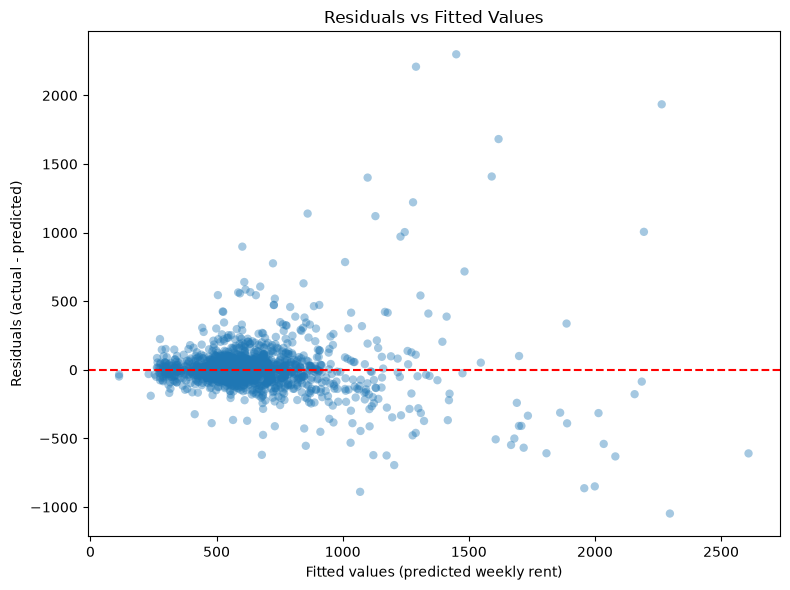

In [20]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Residuals vs fitted values
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.4, edgecolor="none")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted weekly rent)")
plt.ylabel("Residuals (actual - predicted)")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

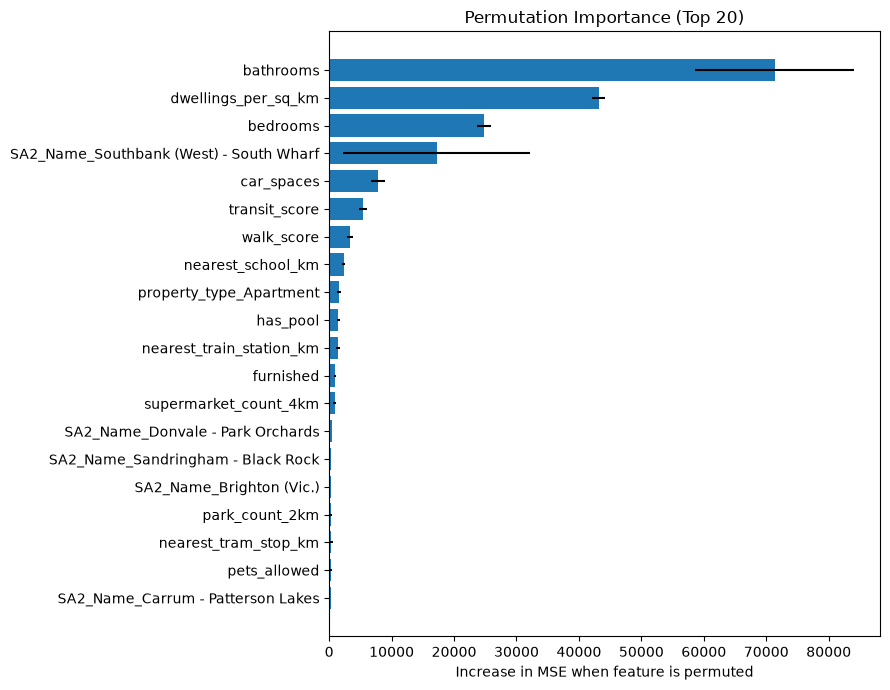

In [21]:
# Permutation importance (on the test set)
perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    scoring="neg_mean_squared_error",
)

top_n = 20
sorted_idx = perm.importances_mean.argsort()[::-1][:top_n]

plt.figure(figsize=(9, 7))
plt.barh(
    X_test.columns[sorted_idx][::-1],
    perm.importances_mean[sorted_idx][::-1],
    xerr=perm.importances_std[sorted_idx][::-1],
)
plt.xlabel("Increase in MSE when feature is permuted")
plt.title(f"Permutation Importance (Top {top_n})")
plt.tight_layout()
plt.show()

# Grouped permutation importance

## The problem with raw feature importances?

Our model has over 500 input columns, and most of them come from one-hot encoding. Each SA2 becomes its own 0/1 column, and `property_type` is split into one column per type. This causes two problems when we look at importances one column at a time:

- **Importance gets diluted.** The effect of "location" is spread across hundreds of SA2 columns, so each one looks small even if location is the single biggest driver of rent. A feature that is stored as one column (like `bedrooms`) will look more important than it really is relative to location.
- **Related features hide each other.** Features that carry similar information (for example, `nearest_school_km` and `school_count_2km`) can split their importance between them. Looking at them individually understates how much the underlying idea, such as school access, matters.

Our research question is about **internal vs external drivers of rent**, not about individual columns, so we need importance measured at the level of meaningful groups.

## What grouped permutation importance does

1. Start with the trained model and measure its error (RMSE) on the held-out test set.
2. Take one group of features, such as all transport columns, and **shuffle their values across listings together**, keeping the rows of every other feature unchanged. This breaks the link between that group and the rent while keeping the group's columns consistent with each other.
3. Re-run the model on the shuffled data and measure the new RMSE.
4. The **increase in RMSE** is the importance of that group. A large increase means the model relied heavily on the group, and a small increase means it barely used it.
5. Repeat the shuffle several times and report the mean and standard deviation, so we can see how stable the result is.

## Why this is better

- **Groups are treated as one unit.** All SA2 columns are shuffled together, so "Location" is scored as a single feature and is not fragmented into hundreds of small ones.
- **It answers the question we are asking.** Groups can be defined to match the internal and external split (for example, size and layout, features and fittings, transport, schools, location), so results can be compared and summed at that level.
- **It is measured on unseen data.** Using the test set shows what the model needs in order to predict well on listings it has not seen, and not just what it memorised during training.
- **Results are in interpretable units.** The importance is the extra dollars per week of prediction error caused by losing the group, which is easier to explain than an abstract impurity score.
- **It is model agnostic.** The method only needs predictions, so it can be reused if we change the model.

## Limitations to keep in mind

- **Importance is not causation.** A high score means the model relies on the group to predict rent, not that changing that feature would change rent by that amount.
- **Overlapping groups share credit.** Dwelling density is constant within each SA2, so it overlaps with the Location group. Shuffling one group can understate its importance because the other still carries some of the same information.
- **Group definitions are a choice.** Different groupings can change the ranking, so the groups should be justified and kept consistent.

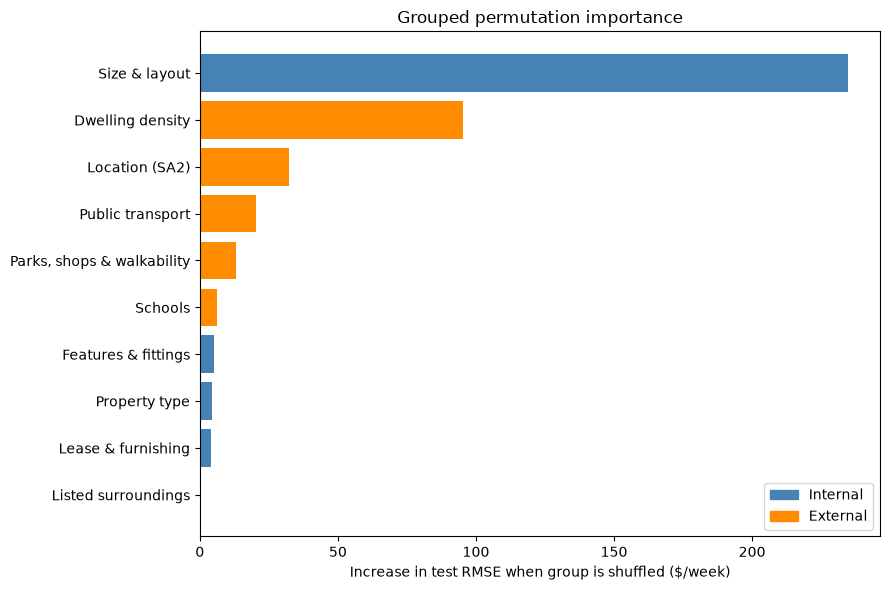

                     group  rmse_increase   std     type
             Size & layout         234.59 26.78 Internal
          Dwelling density          95.22  5.24 External
            Location (SA2)          32.14 30.54 External
          Public transport          20.31  3.11 External
Parks, shops & walkability          13.03  2.01 External
                   Schools           6.23  1.62 External
       Features & fittings           5.09  0.83 Internal
             Property type           4.37  0.92 Internal
        Lease & furnishing           3.97  0.95 Internal
       Listed surroundings           0.17  0.09 External

Total by type (rough comparison only; overlapping groups share credit):
type
External    167.09
Internal    248.03
Name: rmse_increase, dtype: float64


<Figure size 640x480 with 0 Axes>

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

internal = {
    'Property type': [c for c in X.columns if c.startswith('property_type_')],
    'Size & layout': ['bedrooms', 'bathrooms', 'ensuites', 'car_spaces',
                      'num_levels', 'garage', 'has_garage', 'has_rooms', 'has_granny_flat'],
    'Lease & furnishing': ['furnished', 'partially_furnished', 'pets_allowed',
                           'long_term_lease', 'is_build_to_rent'],
    'Features & fittings': ['has_airconditioning', 'has_heating', 'has_insulation', 'has_eco',
                            'has_kitchen', 'has_laundry', 'has_flooring', 'has_internet',
                            'has_pool', 'has_spa', 'has_sport', 'has_disability',
                            'num_security_features'],
}
external = {
    'Location (SA2)': [c for c in X.columns if c.startswith('SA2_Name_')],
    'Dwelling density': ['dwellings_per_sq_km'],
    'Public transport': ['transit_score', 'nearest_train_station_km', 'nearest_tram_stop_km',
                         'tram_stop_capped', 'nearest_bus_stop_km', 'bus_stop_capped'],
    'Schools': ['nearest_school_km', 'school_count_2km'],
    'Parks, shops & walkability': ['walk_score', 'nearest_park_km', 'park_count_2km',
                                   'nearest_supermarket_km', 'supermarket_count_4km'],
    'Listed surroundings': ['has_area', 'has_attractions'],
}
groups = {**internal, **external}

# ---- Check every column is in exactly one group ----
all_grouped = [c for cols in groups.values() for c in cols]
assert len(all_grouped) == len(set(all_grouped)), \
    f"Columns in more than one group: {pd.Series(all_grouped)[pd.Series(all_grouped).duplicated()].tolist()}"
missing = set(X_test.columns) - set(all_grouped)
extra = set(all_grouped) - set(X_test.columns)
assert not missing and not extra, f"Ungrouped: {sorted(missing)} | Not in X: {sorted(extra)}"

# ---- Grouped permutation importance (test set) ----
def group_permutation_importance(model, X_eval, y_eval, groups, n_repeats=10, seed=42):
    rng = np.random.default_rng(seed)
    base_rmse = np.sqrt(mean_squared_error(y_eval, model.predict(X_eval)))
    rows = []
    for name, cols in groups.items():
        increases = []
        for _ in range(n_repeats):
            X_perm = X_eval.copy()
            # one shared row permutation, so the group's columns stay consistent with each other
            X_perm[cols] = X_eval[cols].to_numpy()[rng.permutation(len(X_eval))]
            rmse = np.sqrt(mean_squared_error(y_eval, model.predict(X_perm)))
            increases.append(rmse - base_rmse)
        rows.append((name, np.mean(increases), np.std(increases)))
    return pd.DataFrame(rows, columns=['group', 'rmse_increase', 'std'])

gi = group_permutation_importance(model, X_test, y_test, groups)
gi['type'] = np.where(gi['group'].isin(internal), 'Internal', 'External')
gi = gi.sort_values('rmse_increase')

# ---- Plot ----
colors = gi['type'].map({'Internal': 'steelblue', 'External': 'darkorange'})
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(gi['group'], gi['rmse_increase'],color=colors, capsize=3)
ax.set_xlabel('Increase in test RMSE when group is shuffled ($/week)')
ax.set_title('Grouped permutation importance')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='steelblue'),
                   plt.Rectangle((0, 0), 1, 1, color='darkorange')],
          labels=['Internal', 'External'], loc='lower right')
plt.tight_layout()
plt.show()
plt.savefig('grouped_permutation_importance.png', dpi=300)
print(gi.sort_values('rmse_increase', ascending=False).round(2).to_string(index=False))
print("\nTotal by type (rough comparison only; overlapping groups share credit):")
print(gi.groupby('type')['rmse_increase'].sum().round(2))

In [23]:
print(dwellings_data_forecast.shape)
# one row per SA2, otherwise the join onto properties would duplicate rows
assert not dwellings_data['SA2_Name'].duplicated().any(), "Duplicate SA2 names in 2026 data"
assert not dwellings_data_forecast['SA2_Name'].duplicated().any(), "Duplicate SA2 names in forecast data"
dwellings_data_forecast.head()

(522, 2)


,SA2_Name,dwellings_per_sq_km
0,Alfredton,184.629745
1,Ballarat,512.980963
2,Buninyong,62.025917
3,Delacombe,255.857371
4,Smythes Creek,16.423591


In [24]:
X_new = X.copy()

# Recover each row's SA2 name (merged_data shares X's index; SA2_Name was one-hot encoded out of X)
row_sa2 = merged_data.loc[X_new.index, 'SA2_Name']

# Swap the 2026 dwellings per sq km for the 2031 forecast (same column name, same position)
X_new['dwellings_per_sq_km'] = row_sa2.map(dwellings_data_forecast.set_index('SA2_Name')['dwellings_per_sq_km'])

# Sanity checks
assert len(X_new) == len(X)
assert list(X_new.columns) == list(X.columns)
n_missing = X_new['dwellings_per_sq_km'].isna().sum()
print(f"Rows: {len(X_new)} | missing dwellings_per_sq_km: {n_missing}")
if n_missing:
    print(row_sa2[X_new['dwellings_per_sq_km'].isna()].value_counts())

# Random forests can't extrapolate: count rows whose 2031 value is outside the training range
lo, hi = X['dwellings_per_sq_km'].min(), X['dwellings_per_sq_km'].max()
outside = ((X_new['dwellings_per_sq_km'] < lo) | (X_new['dwellings_per_sq_km'] > hi)).sum()
print(f"Rows outside training dwellings_per_sq_km range [{lo:.1f}, {hi:.1f}]: {outside}")
print(f"Mean dwellings_per_sq_km: {X['dwellings_per_sq_km'].mean():.1f} (2026) -> {X_new['dwellings_per_sq_km'].mean():.1f} (2031)")
X_new.head()

Rows: 9145 | missing dwellings_per_sq_km: 0
Rows outside training dwellings_per_sq_km range [0.1, 28844.4]: 180
Mean dwellings_per_sq_km: 2598.7 (2026) -> 2891.4 (2031)


,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,...,property_type_Flat,property_type_House,property_type_Other,property_type_Serviced Apartment,property_type_Studio,property_type_Terrace,property_type_Townhouse,property_type_Unit,property_type_Villa,property_type_Warehouse
0,1,1,0.0,1,False,False,0,False,False,80,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,0.0,0,False,False,0,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1,1,0.0,0,False,False,0,False,False,100,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0,1,0.0,0,False,False,0,False,False,50,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,2,1,0.0,0,False,False,0,False,False,78,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [25]:
# Forecast weekly rent with the original model (cell 26) on the 2031 dwellings data
assert list(X_new.columns) == list(model.feature_names_in_)
forecasts = pd.Series(model.predict(X_new), index=X_new.index, name='forecasts')

# Compare against the model's predictions on the 2026 features
baseline = pd.Series(model.predict(X), index=X.index)
print(f"Mean predicted rent (2026 dwellings): {baseline.mean():.2f}")
print(f"Mean forecast rent  (2031 dwellings): {forecasts.mean():.2f}")
forecasts.head()

Mean predicted rent (2026 dwellings): 633.36
Mean forecast rent  (2031 dwellings): 641.34


0    558.640000
1    384.650000
2    371.900000
3    260.212917
4    577.930000
Name: forecasts, dtype: float64

# Analysing the projected changes in rent
We see from our forecasts that rent prices are overall expected to increase which is consistent with the reality of how rent prices have been moving in Australia. Below, we will now see which SA2s exhibit the highest increases in rent prices.

                SA2_Name  n_listings  rent_2026  rent_2031  growth_pct  growth_p10  growth_p90  annual_growth_pct
         Tarneit - South          16     551.44     710.54       28.85        0.00       60.19               5.20
         Bundoora - West           8     600.22     753.25       25.50        3.99       54.07               4.65
Craigieburn - North West          16     654.43     815.13       24.55        0.00       66.03               4.49
  Fraser Rise - Plumpton          77     502.36     595.97       18.63        1.36       60.78               3.48
         Sunbury - South          51     536.41     631.51       17.73        0.12       61.46               3.32
                  Melton          29     414.86     483.83       16.62       10.17       22.73               3.12
               Delacombe          38     467.70     540.45       15.55        2.50       29.67               2.93
      Craigieburn - West          15     612.23     704.55       15.08        0.00      

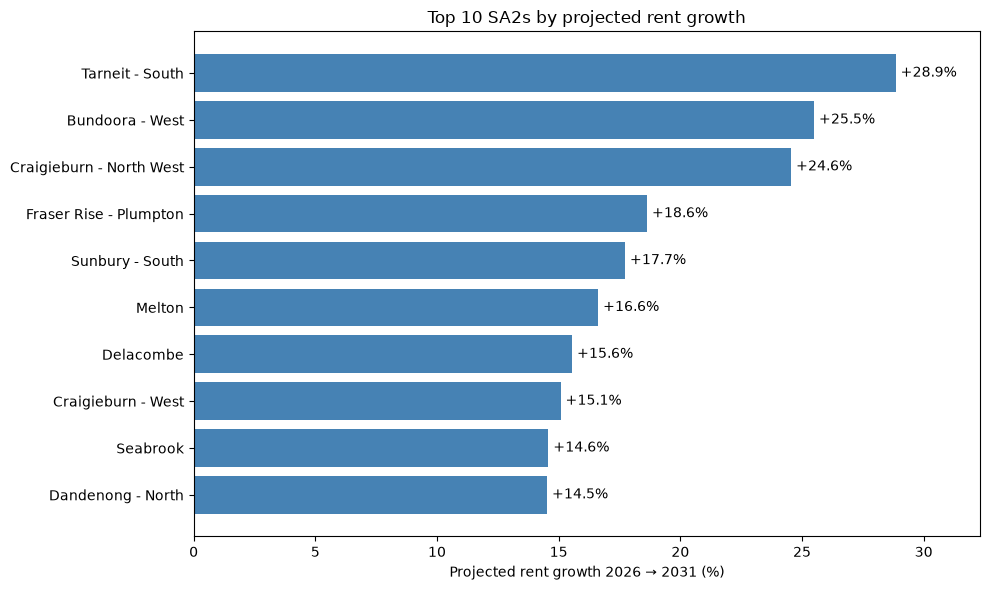

In [26]:
MIN_LISTINGS = 5
YEARS = 5

sa2_labels = merged_data.loc[X.index, 'SA2_Name'].to_numpy()
codes, sa2_names = pd.factorize(sa2_labels)
counts = np.bincount(codes)

Xa = X.to_numpy(dtype=np.float32)
Xn = X_new.to_numpy(dtype=np.float32)

def sa2_means_per_tree(X_arr):
    out = np.empty((len(model.estimators_), len(sa2_names)))
    for i, tree in enumerate(model.estimators_):
        out[i] = (
            np.bincount(
                codes,
                weights=tree.predict(X_arr),
                minlength=len(sa2_names)
            ) / counts
        )
    return out

base_t = sa2_means_per_tree(Xa)    # 2026 features, per tree
new_t  = sa2_means_per_tree(Xn)    # 2031 features, per tree

growth_t = 100 * (new_t / base_t - 1)          # % growth per tree per SA2
point = 100 * (new_t.mean(0) / base_t.mean(0) - 1)

growth = pd.DataFrame({
    'SA2_Name': sa2_names,
    'n_listings': counts,
    'rent_2026': base_t.mean(0),
    'rent_2031': new_t.mean(0),
    'growth_pct': point,
    'growth_p10': np.percentile(growth_t, 10, axis=0),
    'growth_p90': np.percentile(growth_t, 90, axis=0),
})

growth['annual_growth_pct'] = (
    100 * ((1 + growth['growth_pct'] / 100) ** (1 / YEARS) - 1)
)

top10 = (
    growth[growth['n_listings'] >= MIN_LISTINGS]
    .sort_values('growth_pct', ascending=False)
    .head(10)
)

print(top10.round(2).to_string(index=False))

# Reverse order so the highest growth is at the top
t = top10.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    t['SA2_Name'],
    t['growth_pct'],
    color='steelblue'
)

# Add percentage labels next to each bar
for bar, value in zip(bars, t['growth_pct']):
    ax.text(
        bar.get_width() + 0.2,              # position just after bar
        bar.get_y() + bar.get_height() / 2,
        f'+{value:.1f}%',
        va='center',
        ha='left',
        fontsize=10
    )

ax.set_xlabel(
    'Projected rent growth 2026 → 2031 (%)'
)
ax.set_title('Top 10 SA2s by projected rent growth')

# Give the labels some room on the right
ax.set_xlim(right=t['growth_pct'].max() * 1.12)

plt.tight_layout()
plt.savefig('top10_sa2_rent_growth.png', dpi=300)
plt.show()

Matched 476/476 SA2s to boundary geometry.


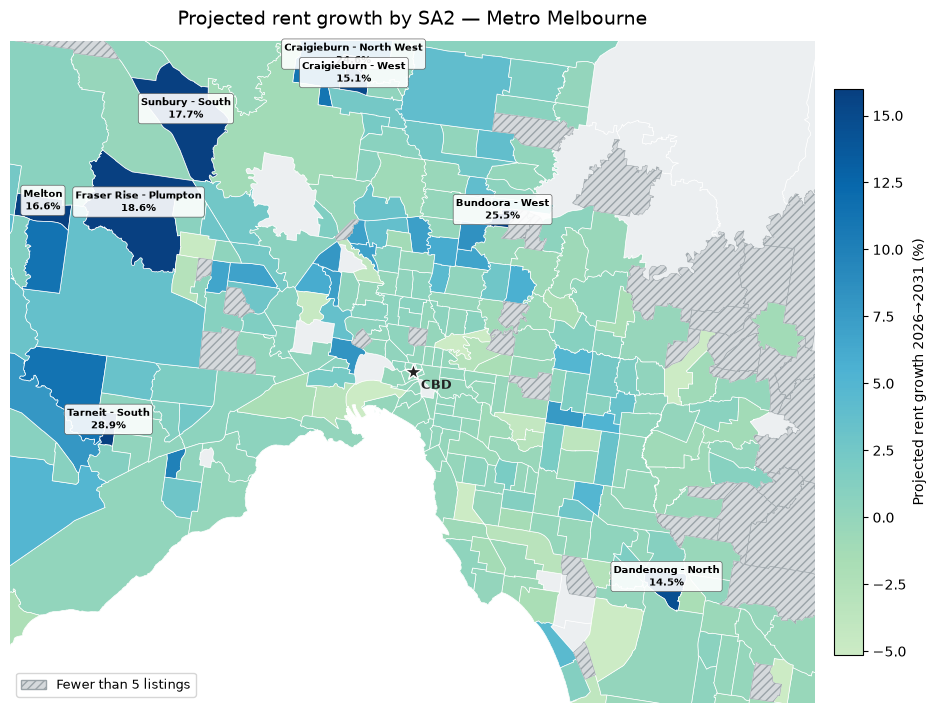

In [27]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# ---------------- Settings you can tweak ----------------
MIN_LISTINGS_FOR_MAP = 5                      # SA2s below this are shown hatched, not coloured
CBD_LON, CBD_LAT = 144.9631, -37.8136         # map is centred on the Melbourne CBD
HALF_WIDTH_DEG, HALF_HEIGHT_DEG = 0.40, 0.26  # ~26 km east-west, ~29 km north-south either side of the CBD
EXCLUDE_FROM_MAP = ['Braybrook', 'Seabrook']      # outlier(s) left off the map
# --------------------------------------------------------

# Join growth results onto SA2 boundaries (geospatial_sa2_data is already loaded above)
sa2_boundaries = (geospatial_sa2_data[['SA2_NAME21', 'geometry']]
                  .rename(columns={'SA2_NAME21': 'SA2_Name'})
                  .dissolve(by='SA2_Name', as_index=False))
if sa2_boundaries.crs is not None and sa2_boundaries.crs.to_epsg() != 4326:
    sa2_boundaries = sa2_boundaries.to_crs(epsg=4326)

growth_geo = sa2_boundaries.merge(growth, on='SA2_Name', how='right')
unmatched = growth_geo.loc[growth_geo['geometry'].isna(), 'SA2_Name'].tolist()
print(f"Matched {len(growth) - len(unmatched)}/{len(growth)} SA2s to boundary geometry.")
if unmatched:
    print(f"WARNING: no boundary found (name mismatch?) for: {unmatched}")
growth_geo = growth_geo[growth_geo['geometry'].notna()].set_geometry('geometry')
growth_geo['reliable'] = growth_geo['n_listings'] >= MIN_LISTINGS_FOR_MAP

# Crop to a frame centred on the CBD
minx, maxx = CBD_LON - HALF_WIDTH_DEG, CBD_LON + HALF_WIDTH_DEG
miny, maxy = CBD_LAT - HALF_HEIGHT_DEG, CBD_LAT + HALF_HEIGHT_DEG
background = sa2_boundaries.cx[minx:maxx, miny:maxy]                       # every SA2, as a light base layer
in_view = growth_geo.cx[minx:maxx, miny:maxy]
in_view = in_view[~in_view['SA2_Name'].isin(EXCLUDE_FROM_MAP)]
reliable, unreliable = in_view[in_view['reliable']], in_view[~in_view['reliable']]

# Colour scale fitted to what's actually on the map (2nd-98th percentile so one extreme SA2 can't wash it out)
vmin, vmax = np.nanpercentile(reliable['growth_pct'], [2, 98])
base = plt.get_cmap('GnBu')
cmap = LinearSegmentedColormap.from_list('GnBu_trunc', base(np.linspace(0.25, 1.0, 256)))  # skips the near-white end

fig, ax = plt.subplots(figsize=(10, 9))
background.plot(ax=ax, facecolor='#eceff1', edgecolor='white', linewidth=0.5)
reliable.plot(column='growth_pct', cmap=cmap, vmin=vmin, vmax=vmax, edgecolor='white', linewidth=0.5, ax=ax,
              legend=True, legend_kwds={'label': 'Projected rent growth 2026\u21922031 (%)', 'shrink': 0.65, 'pad': 0.02})
if len(unreliable):
    unreliable.plot(ax=ax, facecolor='#d5d9dc', edgecolor='#9aa3a8', hatch='////', linewidth=0.4)

ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')  # centroid in lat/lon is fine for placing labels
    # CBD marker for orientation
    ax.plot(CBD_LON, CBD_LAT, marker='*', color='#222222', markersize=13, markeredgecolor='white', zorder=5)
    ax.annotate('CBD', (CBD_LON, CBD_LAT), xytext=(6, -12), textcoords='offset points',
                fontsize=9, fontweight='bold', color='#222222', zorder=5)
    # Label the top-10 SA2s that fall inside the frame
    top10_names = set(growth[growth['n_listings'] >= MIN_LISTINGS_FOR_MAP]
                      .sort_values('growth_pct', ascending=False).head(10)['SA2_Name'])
    for _, row in in_view[in_view['SA2_Name'].isin(top10_names)].iterrows():
        c = row.geometry.centroid
        ax.annotate(f"{row['SA2_Name']}\n{row['growth_pct']:.1f}%", (c.x, c.y), fontsize=7.5, ha='center',
                    fontweight='bold', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#555555', lw=0.5, alpha=0.9))

if len(unreliable):
    ax.legend(handles=[Patch(facecolor='#d5d9dc', edgecolor='#9aa3a8', hatch='////',
                             label=f'Fewer than {MIN_LISTINGS_FOR_MAP} listings')],
              loc='lower left', frameon=True, fontsize=9)

ax.set_title('Projected rent growth by SA2 \u2014 Metro Melbourne', fontsize=14, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()